In [2]:
import pandas as pd
from pathlib import Path

project_dir = Path.cwd().parent

file_path = (
    project_dir
    / "data"
    / "raw"
    / "01_District_wise_crimes_committed_IPC_2001_2012.csv"
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (9017, 33)
Columns: ['STATE/UT', 'DISTRICT', 'YEAR', 'MURDER', 'ATTEMPT TO MURDER', 'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING & ABDUCTION', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY', 'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT', 'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST', 'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT', 'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES', 'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES', 'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES']


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,...,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,...,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,...,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,...,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,...,41,1244,12,109,58,247,0,431,2313,6507


In [ ]:
# 1. Dataset's basic information
print("Dataset Information:")
df.info()

# 2. Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Duplicate records
print("\nTotal duplicate rows:", df.duplicated().sum())

# 4. Unique values in important columns
for col in df.columns[:5]:
    print(f"\n{col}:")
    print(df[col].nunique(), "unique values")

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9017 entries, 0 to 9016
Data columns (total 33 columns):
 #   Column                                               Non-Null Count  Dtype
---  ------                                               --------------  -----
 0   STATE/UT                                             9017 non-null   str  
 1   DISTRICT                                             9017 non-null   str  
 2   YEAR                                                 9017 non-null   int64
 3   MURDER                                               9017 non-null   int64
 4   ATTEMPT TO MURDER                                    9017 non-null   int64
 5   CULPABLE HOMICIDE NOT AMOUNTING TO MURDER            9017 non-null   int64
 6   RAPE                                                 9017 non-null   int64
 7   CUSTODIAL RAPE                                       9017 non-null   int64
 8   OTHER RAPE                                           9017 non-null   int64
 9 

In [4]:
# 1. Total missing values
print("Total missing values:", df.isnull().sum().sum())

# 2. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 3. Districts and states
print("Unique states:", df["STATE/UT"].nunique())
print("Unique districts:", df["DISTRICT"].nunique())

# 4. Year range
print("Year range:", df["YEAR"].min(), "-", df["YEAR"].max())

# 5. Crime totals
crime_cols = df.select_dtypes(include="number").columns.drop(
    "YEAR", errors="ignore"
)
print("\nCrime totals:")
print(df[crime_cols].sum().sort_values(ascending=False).head(10))

Total missing values: 0
Duplicate rows: 0
Unique states: 35
Unique districts: 808
Year range: 2001 - 2012

Crime totals:
TOTAL IPC CRIMES                       47881308
OTHER IPC CRIMES                       19605658
THEFT                                   7001060
HURT/GREVIOUS HURT                      6743752
OTHER THEFT                             4460320
AUTO THEFT                              2540740
BURGLARY                                2234678
CAUSING DEATH BY NEGLIGENCE             2003728
CRUELTY BY HUSBAND OR HIS RELATIVES     1750402
RIOTS                                   1549854
dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

#copy of original dataset
crime = df.copy()

# Cleaning State and district names 
crime["STATE/UT"] = crime["STATE/UT"].astype(str).str.strip().str.upper()
crime["DISTRICT"] = crime["DISTRICT"].astype(str).str.strip().str.upper()

# To Identify Invalid district 
invalid_names = ["", "NAN", "NULL", "TOTAL", "ZZ TOTAL"]

print("Rows before cleaning:", len(crime))

crime = crime[
    ~crime["DISTRICT"].isin(invalid_names)
].copy()

# To identify Crime-count columns 
crime_cols = [
    c for c in crime.select_dtypes(include="number").columns
    if c != "YEAR"
]

# To check Negative crime counts 
print("Negative values in crime columns:")
print((crime[crime_cols] < 0).sum().sum())

# To aggregate on the basis of District + state + year   
district_year = (
    crime.groupby(["STATE/UT", "DISTRICT", "YEAR"], as_index=False)[crime_cols]
    .sum()
)

print("Cleaned rows:", len(crime))
print("District-year rows:", len(district_year))
display(district_year.head())

# To save in Processed folder 
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

district_year.to_csv(
    output_dir / "crime_district_year_cleaned.csv",
    index=False
)

print("Saved:", output_dir / "crime_district_year_cleaned.csv")

Rows before cleaning: 9017
Negative values in crime columns:
0
Cleaned rows: 8609
District-year rows: 8608


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,A & N ISLANDS,A AND N ISLANDS,2007,15,19,1,3,0,3,12,...,11,99,1,21,2,18,0,4,337,807
1,A & N ISLANDS,ANDAMAN,2001,13,0,0,3,0,3,2,...,4,113,0,18,1,9,0,0,310,637
2,A & N ISLANDS,ANDAMAN,2002,14,3,0,1,0,1,2,...,2,92,0,16,3,4,0,0,316,580
3,A & N ISLANDS,ANDAMAN,2003,16,4,1,2,0,2,2,...,7,107,0,9,2,7,0,0,299,611
4,A & N ISLANDS,ANDAMAN,2004,13,1,2,10,0,10,3,...,8,102,0,5,3,5,0,6,373,721


Saved: ..\data\processed\crime_district_year_cleaned.csv


In [ ]:
from pathlib import Path
import pandas as pd

# Load Cleaned dataset 
input_path = Path("../data/processed/crime_district_year_cleaned.csv")
crime = pd.read_csv(input_path)

# Crime count columns: To exclude YEAR 
crime_cols = [
    c for c in crime.select_dtypes(include="number").columns
    if c != "YEAR"
]

# District ke liye sabhi available years ke crime counts add karo
district_crime = (
    crime.groupby(["STATE/UT", "DISTRICT"], as_index=False)[crime_cols]
    .sum()
)

# Total recorded crimes across available categories
district_crime["total_crimes"] = district_crime[crime_cols].sum(axis=1)

# Relative score: 0-100
# Lowest recorded count = 100; highest = 0
min_crime = district_crime["total_crimes"].min()
max_crime = district_crime["total_crimes"].max()

if max_crime == min_crime:
    district_crime["crime_score"] = 100.0
else:
    district_crime["crime_score"] = (
        100 * (max_crime - district_crime["total_crimes"])
        / (max_crime - min_crime)
    ).round(2)

# Save
output_path = Path("../data/processed/crime_district_scores.csv")
district_crime.to_csv(output_path, index=False)

print("Districts:", len(district_crime))
print("Saved:", output_path)
display(
    district_crime[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].sort_values("total_crimes").head(10)
)

Districts: 828
Saved: ..\data\processed\crime_district_scores.csv


,STATE/UT,DISTRICT,total_crimes,crime_score
294,JAMMU & KASHMIR,RAILWAYS KATRA,6,100.0
699,TRIPURA,G.R.P.,15,100.0
494,MANIPUR,CID,18,100.0
295,JAMMU & KASHMIR,RAILWAYS KMR,20,100.0
257,HIMACHAL PRADESH,CID,29,100.0
60,ASSAM,BIEO,32,100.0
701,TRIPURA,GRP,50,100.0
2,A & N ISLANDS,CAR,53,100.0
277,JAMMU & KASHMIR,CRIME KASHMIR,64,100.0
292,JAMMU & KASHMIR,RAILWAYS JAMMU,64,100.0


In [7]:
import pandas as pd
from pathlib import Path

# Saved crime scores load karo
crime = pd.read_csv(
    Path("../data/processed/crime_district_scores.csv")
)

# District aur state names check karo
print("Total district records:", len(crime))
print("\nSample state-district names:")

display(
    crime[["STATE/UT", "DISTRICT", "crime_score"]].head(10)
)

print("\nMissing state/district names:")
print(crime[["STATE/UT", "DISTRICT"]].isna().sum())

print("\nUnique states:", crime["STATE/UT"].nunique())

Total district records: 828

Sample state-district names:


,STATE/UT,DISTRICT,crime_score
0,A & N ISLANDS,A AND N ISLANDS,99.89
1,A & N ISLANDS,ANDAMAN,98.96
2,A & N ISLANDS,CAR,100.00
3,A & N ISLANDS,NICOBAR,99.97
4,A & N ISLANDS,NORTH,99.98
5,A & N ISLANDS,SOUTH,99.92
6,ANDHRA PRADESH,ADILABAD,91.55
7,ANDHRA PRADESH,ANANTAPUR,91.69
8,ANDHRA PRADESH,CHITTOOR,89.32
9,ANDHRA PRADESH,CUDDAPAH,92.04



Missing state/district names:
STATE/UT    0
DISTRICT    0
dtype: int64

Unique states: 35


In [8]:
# Check crime score statistics
print("Crime score summary:")
display(crime["crime_score"].describe())

# Check highest-scoring districts
top_districts = crime.sort_values(
    "crime_score", ascending=False
).head(10)

display(top_districts)

Crime score summary:


count    828.000000
mean      95.775121
std        5.734576
min        0.000000
25%       94.222500
50%       97.175000
75%       99.100000
max      100.000000
Name: crime_score, dtype: float64

,STATE/UT,DISTRICT,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS,...,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES,total_crimes,crime_score
701,TRIPURA,GRP,2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,5,21,50,100.0
699,TRIPURA,G.R.P.,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,6,15,100.0
494,MANIPUR,CID,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,9,18,100.0
295,JAMMU & KASHMIR,RAILWAYS KMR,0,0,0,0,0,0,0,0,...,0,2,0,0,0,0,7,10,20,100.0
277,JAMMU & KASHMIR,CRIME KASHMIR,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,32,64,100.0
292,JAMMU & KASHMIR,RAILWAYS JAMMU,0,3,0,0,0,0,0,0,...,0,0,1,0,0,2,13,29,64,100.0
294,JAMMU & KASHMIR,RAILWAYS KATRA,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,2,6,100.0
257,HIMACHAL PRADESH,CID,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,12,14,29,100.0
60,ASSAM,BIEO,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,16,32,100.0
2,A & N ISLANDS,CAR,2,0,0,0,0,0,1,1,...,0,1,0,0,0,1,8,24,53,100.0


In [9]:
# Check crime score distribution
print("Minimum score:", crime["crime_score"].min())
print("Maximum score:", crime["crime_score"].max())
print("Unique scores:", crime["crime_score"].nunique())

print(
    "Districts with score 100:",
    (crime["crime_score"].round(2) == 100).sum()
)

display(
    crime["crime_score"]
    .value_counts()
    .head(10)
)

Minimum score: 0.0
Maximum score: 100.0
Unique scores: 542
Districts with score 100: 10


crime_score
100.00    10
99.89      7
99.98      7
98.52      6
99.90      5
99.95      5
99.43      5
97.35      5
99.86      5
98.61      5
Name: count, dtype: int64

In [4]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.

In [1]:
import pandas as pd
from pathlib import Path

# Project folder se cleaned crime data load karo
file_path = Path("../data/processed/crime_district_year_cleaned.csv")

crime = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", crime.shape)
print("Columns:", crime.columns.tolist())

display(crime.head())

Dataset loaded successfully!
Shape: (8608, 33)
Columns: ['STATE/UT', 'DISTRICT', 'YEAR', 'MURDER', 'ATTEMPT TO MURDER', 'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING & ABDUCTION', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY', 'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT', 'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST', 'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT', 'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES', 'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES', 'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES']


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,A & N ISLANDS,A AND N ISLANDS,2007,15,19,1,3,0,3,12,...,11,99,1,21,2,18,0,4,337,807
1,A & N ISLANDS,ANDAMAN,2001,13,0,0,3,0,3,2,...,4,113,0,18,1,9,0,0,310,637
2,A & N ISLANDS,ANDAMAN,2002,14,3,0,1,0,1,2,...,2,92,0,16,3,4,0,0,316,580
3,A & N ISLANDS,ANDAMAN,2003,16,4,1,2,0,2,2,...,7,107,0,9,2,7,0,0,299,611
4,A & N ISLANDS,ANDAMAN,2004,13,1,2,10,0,10,3,...,8,102,0,5,3,5,0,6,373,721


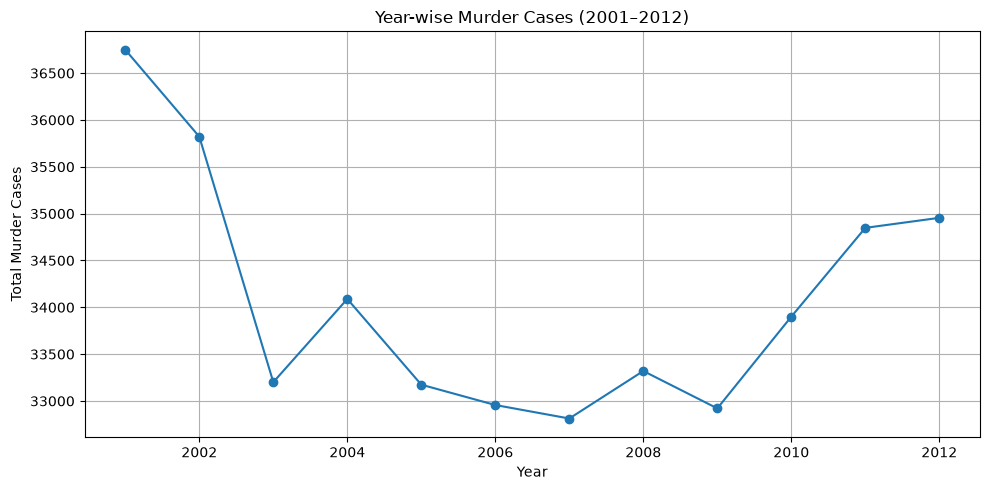

In [2]:
import matplotlib.pyplot as plt

yearly_crimes = crime.groupby("YEAR")["MURDER"].sum()

plt.figure(figsize=(10, 5))
yearly_crimes.plot(kind="line", marker="o")

plt.title("Year-wise Murder Cases (2001–2012)")
plt.xlabel("Year")
plt.ylabel("Total Murder Cases")
plt.grid(True)
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/processed/crime_district_scores.csv")
district_crime = pd.read_csv(file_path)

print("Total district records:", len(district_crime))
print("\nCrime score summary:")
display(district_crime["crime_score"].describe())

print("\n10 districts with highest crime scores:")
display(
    district_crime.sort_values(
        "crime_score", ascending=False
    )[["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]]
    .head(10)
)

Total district records: 828

Crime score summary:


count    828.000000
mean      95.775121
std        5.734576
min        0.000000
25%       94.222500
50%       97.175000
75%       99.100000
max      100.000000
Name: crime_score, dtype: float64


10 districts with highest crime scores:


,STATE/UT,DISTRICT,total_crimes,crime_score
701,TRIPURA,GRP,50,100.0
699,TRIPURA,G.R.P.,15,100.0
494,MANIPUR,CID,18,100.0
295,JAMMU & KASHMIR,RAILWAYS KMR,20,100.0
277,JAMMU & KASHMIR,CRIME KASHMIR,64,100.0
292,JAMMU & KASHMIR,RAILWAYS JAMMU,64,100.0
294,JAMMU & KASHMIR,RAILWAYS KATRA,6,100.0
257,HIMACHAL PRADESH,CID,29,100.0
60,ASSAM,BIEO,32,100.0
2,A & N ISLANDS,CAR,53,100.0


In [4]:
print("10 districts with highest crime scores:")

display(
    district_crime.sort_values(
        "crime_score", ascending=False
    )[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].head(10)
)

10 districts with highest crime scores:


,STATE/UT,DISTRICT,total_crimes,crime_score
701,TRIPURA,GRP,50,100.0
699,TRIPURA,G.R.P.,15,100.0
494,MANIPUR,CID,18,100.0
295,JAMMU & KASHMIR,RAILWAYS KMR,20,100.0
277,JAMMU & KASHMIR,CRIME KASHMIR,64,100.0
292,JAMMU & KASHMIR,RAILWAYS JAMMU,64,100.0
294,JAMMU & KASHMIR,RAILWAYS KATRA,6,100.0
257,HIMACHAL PRADESH,CID,29,100.0
60,ASSAM,BIEO,32,100.0
2,A & N ISLANDS,CAR,53,100.0


In [5]:
# District names mein special-unit jaise records check karna

keywords = ["GRP", "RAILWAY", "CID", "CRIME"]

for keyword in keywords:
    matches = district_crime[
        district_crime["DISTRICT"]
        .astype(str)
        .str.contains(keyword, case=False, na=False)
    ]

    print(f"\n{keyword}: {len(matches)} matching records")
    display(matches[["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]].head(10))


GRP: 4 matching records


,STATE/UT,DISTRICT,total_crimes,crime_score
145,CHHATTISGARH,GRP RAIPUR,10712,99.30
174,DELHI UT,GRP(RLY),18327,98.80
236,HARYANA,GRP,28053,98.17
701,TRIPURA,GRP,50,100.00



RAILWAY: 7 matching records


,STATE/UT,DISTRICT,total_crimes,crime_score
291,JAMMU & KASHMIR,RAILWAYS,601,99.96
292,JAMMU & KASHMIR,RAILWAYS JAMMU,64,100.00
293,JAMMU & KASHMIR,RAILWAYS KASHMIR,105,99.99
294,JAMMU & KASHMIR,RAILWAYS KATRA,6,100.00
295,JAMMU & KASHMIR,RAILWAYS KMR,20,100.00
358,KARNATAKA,RAILWAYS,20533,98.66
383,KERALA,RAILWAYS,8773,99.43



CID: 4 matching records


,STATE/UT,DISTRICT,total_crimes,crime_score
201,GUJARAT,CID CRIME,112,99.99
257,HIMACHAL PRADESH,CID,29,100.00
366,KERALA,CBCID,2738,99.82
494,MANIPUR,CID,18,100.00



CRIME: 5 matching records


,STATE/UT,DISTRICT,total_crimes,crime_score
169,DELHI UT,CRIME BRANCH,811,99.95
201,GUJARAT,CID CRIME,112,99.99
276,JAMMU & KASHMIR,CRIME JAMMU,740,99.95
277,JAMMU & KASHMIR,CRIME KASHMIR,64,100.00
278,JAMMU & KASHMIR,CRIME SRINAGAR,1374,99.91


In [6]:
# Special-unit records ki list
keywords = [
    "GRP", "RAILWAY", "CID",
    "CRIME", "RLY", "POLICE"
]

pattern = "|".join(keywords)

special_records = district_crime[
    district_crime["DISTRICT"]
    .astype(str)
    .str.contains(pattern, case=False, na=False)
].copy()

print("Potential special-unit records:", len(special_records))

display(
    special_records[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].sort_values(["STATE/UT", "DISTRICT"])
)

Potential special-unit records: 41


,STATE/UT,DISTRICT,total_crimes,crime_score
12,ANDHRA PRADESH,GUNTAKAL RLY.,8568,99.44
28,ANDHRA PRADESH,SECUNDERABAD RLY.,17161,98.88
33,ANDHRA PRADESH,VIJAYAWADA RLY.,14672,99.04
104,BIHAR,JAMALPUR RLY.,7306,99.52
108,BIHAR,KATIHAR RLY.,13096,99.14
117,BIHAR,MUZAFFARPUR RLY.,18135,98.81
122,BIHAR,PATNA RLY.,33734,97.79
145,CHHATTISGARH,GRP RAIPUR,10712,99.30
169,DELHI UT,CRIME BRANCH,811,99.95
173,DELHI UT,G.R.P.(RLY),19164,98.75


In [7]:
# District names ki frequency check karna
print("District names mein common entries:")

display(
    district_crime["DISTRICT"]
    .value_counts()
    .head(30)
    .reset_index()
)

District names mein common entries:


,DISTRICT,count
0,G.R.P.,5
1,NORTH,4
2,SOUTH,4
3,WEST,3
4,RAILWAYS,3
5,BALRAMPUR,2
6,BILASPUR,2
7,EAST,2
8,GRP,2
9,CID,2


In [8]:
display(
    district_crime[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ]
    .sort_values("total_crimes", ascending=True)
    .head(20)
)

,STATE/UT,DISTRICT,total_crimes,crime_score
294,JAMMU & KASHMIR,RAILWAYS KATRA,6,100.00
699,TRIPURA,G.R.P.,15,100.00
494,MANIPUR,CID,18,100.00
295,JAMMU & KASHMIR,RAILWAYS KMR,20,100.00
257,HIMACHAL PRADESH,CID,29,100.00
60,ASSAM,BIEO,32,100.00
701,TRIPURA,GRP,50,100.00
2,A & N ISLANDS,CAR,53,100.00
277,JAMMU & KASHMIR,CRIME KASHMIR,64,100.00
292,JAMMU & KASHMIR,RAILWAYS JAMMU,64,100.00


In [9]:
# Special-unit records ko identify karna
special_keywords = [
    "RAILWAY", "RLY", "G.R.P", "GRP",
    "CID", "CRIME", "C.I.D"
]

special_mask = district_crime["DISTRICT"].str.contains(
    "|".join(special_keywords),
    case=False,
    na=False
)

special_units = district_crime[special_mask].copy()
district_candidates = district_crime[~special_mask].copy()

print("Potential special-unit records:", len(special_units))
print("Remaining district candidates:", len(district_candidates))

display(
    special_units[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].head(15)
)

Potential special-unit records: 55
Remaining district candidates: 773


,STATE/UT,DISTRICT,total_crimes,crime_score
12,ANDHRA PRADESH,GUNTAKAL RLY.,8568,99.44
28,ANDHRA PRADESH,SECUNDERABAD RLY.,17161,98.88
33,ANDHRA PRADESH,VIJAYAWADA RLY.,14672,99.04
62,ASSAM,C.I.D.,794,99.95
69,ASSAM,G.R.P.,8793,99.43
104,BIHAR,JAMALPUR RLY.,7306,99.52
108,BIHAR,KATIHAR RLY.,13096,99.14
117,BIHAR,MUZAFFARPUR RLY.,18135,98.81
122,BIHAR,PATNA RLY.,33734,97.79
145,CHHATTISGARH,GRP RAIPUR,10712,99.30


In [10]:
# District candidates ki copy
district_scores = district_candidates.copy()

# Minimum aur maximum recorded crimes
min_crime = district_scores["total_crimes"].min()
max_crime = district_scores["total_crimes"].max()

# Crime score dobara calculate karna
if max_crime == min_crime:
    district_scores["crime_score"] = 100.0
else:
    district_scores["crime_score"] = (
        100 * (max_crime - district_scores["total_crimes"])
        / (max_crime - min_crime)
    ).round(2)

# Results check karna
print("District candidates:", len(district_scores))
print("Minimum crimes:", min_crime)
print("Maximum crimes:", max_crime)

display(
    district_scores[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ]
    .sort_values("total_crimes")
    .head(10)
)

District candidates: 773
Minimum crimes: 32
Maximum crimes: 1529401


,STATE/UT,DISTRICT,total_crimes,crime_score
60,ASSAM,BIEO,32,100.00
2,A & N ISLANDS,CAR,53,100.00
40,ARUNACHAL PRADESH,ANJAW,184,99.99
521,NAGALAND,LONGLENG,187,99.99
4,A & N ISLANDS,NORTH,247,99.99
189,DELHI UT,SPL CELL,267,99.98
56,ARUNACHAL PRADESH,UPPER DIBANG VALLEY,316,99.98
184,DELHI UT,S.T.F.,319,99.98
74,ASSAM,HAMREN,355,99.98
190,DELHI UT,STF,364,99.98


In [11]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "crime_district_scores_cleaned.csv"

district_scores.to_csv(output_path, index=False)

print("File saved successfully!")
print("Location:", output_path.resolve())
print("Total records:", len(district_scores))

File saved successfully!
Location: C:\Users\Admin\OneDrive\Desktop\TY Project\data\processed\crime_district_scores_cleaned.csv
Total records: 773


In [12]:
# Load the saved file and verify its contents
from pathlib import Path
import pandas as pd

file_path = Path("../data/processed/crime_district_scores_cleaned.csv")

# Check whether the file exists before loading it
print("File exists:", file_path.exists())

# Load the dataset
check_df = pd.read_csv(file_path)

# Display dataset information
print("Dataset shape:", check_df.shape)
print("Columns:", check_df.columns.tolist())

# Display the first 10 district records
display(
    check_df[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].head(10)
)

File exists: True
Dataset shape: (773, 34)
Columns: ['STATE/UT', 'DISTRICT', 'MURDER', 'ATTEMPT TO MURDER', 'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING & ABDUCTION', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY', 'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT', 'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST', 'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT', 'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES', 'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES', 'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES', 'total_crimes', 'crime_score']


,STATE/UT,DISTRICT,total_crimes,crime_score
0,A & N ISLANDS,A AND N ISLANDS,1741,99.89
1,A & N ISLANDS,ANDAMAN,15837,98.97
2,A & N ISLANDS,CAR,53,100.00
3,A & N ISLANDS,NICOBAR,496,99.97
4,A & N ISLANDS,NORTH,247,99.99
5,A & N ISLANDS,SOUTH,1157,99.93
6,ANDHRA PRADESH,ADILABAD,129308,91.55
7,ANDHRA PRADESH,ANANTAPUR,127038,91.70
8,ANDHRA PRADESH,CHITTOOR,163294,89.32
9,ANDHRA PRADESH,CUDDAPAH,121775,92.04


In [13]:
# Check for possible special-unit records
special_keywords = [
    "GRP",
    "RAILWAY",
    "RAILWAYS",
    "CID",
    "CRIME BRANCH",
    "C.I.D."
]

# Identify records that may represent special units
special_mask = check_df["DISTRICT"].astype(str).str.upper().str.contains(
    "|".join(special_keywords),
    regex=True,
    na=False
)

special_records = check_df[special_mask]

print("Total records:", len(check_df))
print("Potential special-unit records:", len(special_records))
print("Remaining district candidates:", len(check_df) - len(special_records))

display(
    special_records[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].head(15)
)

Total records: 773
Potential special-unit records: 0
Remaining district candidates: 773


,STATE/UT,DISTRICT,total_crimes,crime_score


In [14]:
# Search for common railway and police-unit names

keywords = [
    "GRP",
    "RAIL",
    "RAILWAY",
    "CID",
    "C.I.D",
    "CRIME BRANCH",
    "POLICE"
]

district_names = check_df["DISTRICT"].astype(str).str.upper()

for keyword in keywords:
    matches = check_df[
        district_names.str.contains(keyword, regex=False, na=False)
    ]

    print(f"\n{keyword}: {len(matches)} matching records")

    if not matches.empty:
        display(matches[["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]].head(5))


GRP: 0 matching records

RAIL: 0 matching records

RAILWAY: 0 matching records

CID: 0 matching records

C.I.D: 0 matching records

CRIME BRANCH: 0 matching records

POLICE: 1 matching records


,STATE/UT,DISTRICT,total_crimes,crime_score
236,HIMACHAL PRADESH,BADDIPOLICEDIST,4073,99.74


In [15]:
# Inspect the police-related record before making any changes

police_record = check_df[
    check_df["DISTRICT"].astype(str).str.upper().str.contains(
        "POLICE", regex=False, na=False
    )
]

display(police_record)

print("Number of matching records:", len(police_record))

,STATE/UT,DISTRICT,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS,...,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES,total_crimes,crime_score
236,HIMACHAL PRADESH,BADDIPOLICEDIST,32,16,0,27,0,27,39,30,...,1,25,1,38,0,199,423,1913,4073,99.74


Number of matching records: 1


In [16]:
# Review district names that may represent special units

review_keywords = [
    "GRP",
    "RAIL",
    "CID",
    "C.I.D",
    "POLICE",
    "CRIME",
    "RLY",
    "RAILWAY",
    "RAILWAYS"
]

district_names = check_df["DISTRICT"].astype(str).str.upper()

review_mask = district_names.apply(
    lambda name: any(keyword in name for keyword in review_keywords)
)

review_df = check_df.loc[
    review_mask,
    ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
].drop_duplicates()

print("Records requiring manual review:", len(review_df))
display(review_df)

Records requiring manual review: 1


,STATE/UT,DISTRICT,total_crimes,crime_score
236,HIMACHAL PRADESH,BADDIPOLICEDIST,4073,99.74


In [17]:
# Separate the record for manual review

review_df.to_csv(
    "../data/processed/crime_records_for_review.csv",
    index=False
)

print("Review file saved successfully!")
print("Records saved for review:", len(review_df))

Review file saved successfully!
Records saved for review: 1


In [18]:
# Load the cleaned crime-score dataset
from pathlib import Path
import pandas as pd

file_path = Path("../data/processed/crime_district_scores_cleaned.csv")
check_df = pd.read_csv(file_path)

# Check for duplicate state-district combinations
duplicate_mask = check_df.duplicated(
    subset=["STATE/UT", "DISTRICT"],
    keep=False
)

duplicates = check_df[duplicate_mask].sort_values(
    ["STATE/UT", "DISTRICT"]
)

print("Total records:", len(check_df))
print("Duplicate state-district records:", len(duplicates))

# Display duplicate records for manual review
display(
    duplicates[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].head(20)
)

Total records: 773
Duplicate state-district records: 0


,STATE/UT,DISTRICT,total_crimes,crime_score


In [19]:
# Display sample district names for manual review
display(
    district_candidates[["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]]
    .sort_values(["STATE/UT", "DISTRICT"])
    .head(30)
)

,STATE/UT,DISTRICT,total_crimes,crime_score
0,A & N ISLANDS,A AND N ISLANDS,1741,99.89
1,A & N ISLANDS,ANDAMAN,15837,98.96
2,A & N ISLANDS,CAR,53,100.00
3,A & N ISLANDS,NICOBAR,496,99.97
4,A & N ISLANDS,NORTH,247,99.98
5,A & N ISLANDS,SOUTH,1157,99.92
6,ANDHRA PRADESH,ADILABAD,129308,91.55
7,ANDHRA PRADESH,ANANTAPUR,127038,91.69
8,ANDHRA PRADESH,CHITTOOR,163294,89.32
9,ANDHRA PRADESH,CUDDAPAH,121775,92.04


In [20]:
# Check the current cleaned dataset columns and sample records
print("Dataset shape:", district_candidates.shape)

print("\nAvailable columns:")
print(district_candidates.columns.tolist())

print("\nSample records:")
display(
    district_candidates[
        ["STATE/UT", "DISTRICT", "total_crimes", "crime_score"]
    ].head(5)
)

Dataset shape: (773, 34)

Available columns:
['STATE/UT', 'DISTRICT', 'MURDER', 'ATTEMPT TO MURDER', 'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING & ABDUCTION', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY', 'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT', 'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST', 'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT', 'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES', 'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES', 'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES', 'total_crimes', 'crime_score']

Sample records:


,STATE/UT,DISTRICT,total_crimes,crime_score
0,A & N ISLANDS,A AND N ISLANDS,1741,99.89
1,A & N ISLANDS,ANDAMAN,15837,98.96
2,A & N ISLANDS,CAR,53,100.00
3,A & N ISLANDS,NICOBAR,496,99.97
4,A & N ISLANDS,NORTH,247,99.98


In [21]:
# Create a unique list of state and district names
district_list = (
    district_candidates[["STATE/UT", "DISTRICT"]]
    .drop_duplicates()
    .sort_values(["STATE/UT", "DISTRICT"])
    .reset_index(drop=True)
)

# Save the district list for coordinate mapping
from pathlib import Path

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "district_coordinate_mapping.csv"
district_list["latitude"] = None
district_list["longitude"] = None
district_list["coordinate_source"] = None

district_list.to_csv(output_file, index=False)

print("Total districts to map:", len(district_list))
print("Mapping file saved to:", output_file)
display(district_list.head(10))

Total districts to map: 773
Mapping file saved to: ..\data\processed\district_coordinate_mapping.csv


,STATE/UT,DISTRICT,latitude,longitude,coordinate_source
0,A & N ISLANDS,A AND N ISLANDS,None,None,None
1,A & N ISLANDS,ANDAMAN,None,None,None
2,A & N ISLANDS,CAR,None,None,None
3,A & N ISLANDS,NICOBAR,None,None,None
4,A & N ISLANDS,NORTH,None,None,None
5,A & N ISLANDS,SOUTH,None,None,None
6,ANDHRA PRADESH,ADILABAD,None,None,None
7,ANDHRA PRADESH,ANANTAPUR,None,None,None
8,ANDHRA PRADESH,CHITTOOR,None,None,None
9,ANDHRA PRADESH,CUDDAPAH,None,None,None


In [22]:
# Check the district mapping file before adding coordinates
import pandas as pd
from pathlib import Path

mapping_file = Path("../data/processed/district_coordinate_mapping.csv")
mapping_df = pd.read_csv(mapping_file)

print("Total mapping records:", len(mapping_df))
print("Missing latitude:", mapping_df["latitude"].isna().sum())
print("Missing longitude:", mapping_df["longitude"].isna().sum())

print("\nSample districts:")
display(mapping_df[["STATE/UT", "DISTRICT"]].head(10))

Total mapping records: 773
Missing latitude: 773
Missing longitude: 773

Sample districts:


,STATE/UT,DISTRICT
0,A & N ISLANDS,A AND N ISLANDS
1,A & N ISLANDS,ANDAMAN
2,A & N ISLANDS,CAR
3,A & N ISLANDS,NICOBAR
4,A & N ISLANDS,NORTH
5,A & N ISLANDS,SOUTH
6,ANDHRA PRADESH,ADILABAD
7,ANDHRA PRADESH,ANANTAPUR
8,ANDHRA PRADESH,CHITTOOR
9,ANDHRA PRADESH,CUDDAPAH


In [23]:
# Check how many state-district combinations need coordinate mapping
import pandas as pd

mapping_df = pd.read_csv(
    "../data/processed/district_coordinate_mapping.csv"
)

print("Total records:", len(mapping_df))
print("Unique states/UTs:", mapping_df["STATE/UT"].nunique())
print("Unique district names:", mapping_df["DISTRICT"].nunique())

print("\nRecords per state/UT:")
display(
    mapping_df.groupby("STATE/UT")["DISTRICT"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

Total records: 773
Unique states/UTs: 35
Unique district names: 760

Records per state/UT:


STATE/UT
UTTAR PRADESH     76
MADHYA PRADESH    50
RAJASTHAN         44
MAHARASHTRA       43
BIHAR             40
TAMIL NADU        40
ODISHA            36
PUNJAB            34
KARNATAKA         34
GUJARAT           32
Name: DISTRICT, dtype: int64

In [1]:
# Test connection to the alternative district map service
import requests

url = "https://livingatlas.esri.in/server/rest/services/LivingAtlas/IND_AdminBoundary/MapServer"

try:
    response = requests.get(
        url,
        params={"f": "json"},
        timeout=20
    )

    print("HTTP status:", response.status_code)

    if response.ok:
        data = response.json()
        print("Service name:", data.get("mapName"))
        print("\nAvailable map layers:")

        for layer in data.get("layers", []):
            print(layer["id"], "-", layer["name"])
    else:
        print("Service returned an error.")

except requests.RequestException as error:
    print("Connection error:", error)

HTTP status: 200
Service name: Layers

Available map layers:
0 - Country
1 - State
2 - District


In [2]:
# Inspect the district layer fields and sample records
import requests

layer_url = (
    "https://livingatlas.esri.in/server/rest/services/"
    "LivingAtlas/IND_AdminBoundary/MapServer/2"
)

try:
    response = requests.get(
        layer_url,
        params={"f": "json"},
        timeout=20
    )
    response.raise_for_status()
    layer_data = response.json()

    print("Layer name:", layer_data.get("name"))
    print("\nAvailable fields:")

    for field in layer_data.get("fields", []):
        print(field["name"], "-", field.get("alias"))

    query_url = layer_url + "/query"
    query_response = requests.get(
        query_url,
        params={
            "where": "1=1",
            "outFields": "*",
            "returnGeometry": "false",
            "resultRecordCount": 5,
            "f": "json"
        },
        timeout=20
    )
    query_response.raise_for_status()
    query_data = query_response.json()

    print("\nSample district records:")
    for feature in query_data.get("features", []):
        print(feature["attributes"])

except (requests.RequestException, ValueError) as error:
    print("Error while reading district layer:", error)

Layer name: District

Available fields:
objectid - objectid
district - District
state - State
country - Country
shape - shape
st_perimeter(shape) - st_perimeter(shape)

Sample district records:
{'objectid': 1, 'district': 'Changlang', 'state': 'Arunachal Pradesh', 'country': 'India', 'st_perimeter(shape)': 632350.0427511813}
{'objectid': 2, 'district': 'Chatra', 'state': 'Jharkhand', 'country': 'India', 'st_perimeter(shape)': 584305.8250651036}
{'objectid': 3, 'district': 'Etah', 'state': 'Uttar Pradesh', 'country': 'India', 'st_perimeter(shape)': 568724.360296771}
{'objectid': 4, 'district': 'Etawah', 'state': 'Uttar Pradesh', 'country': 'India', 'st_perimeter(shape)': 373559.937089058}
{'objectid': 5, 'district': 'Faridabad', 'state': 'Haryana', 'country': 'India', 'st_perimeter(shape)': 175269.8213567465}


In [5]:
# Inspect the matching results and available columns
print("Columns in checked_df:")
print(checked_df.columns.tolist())

print("\nNumber of rows:", len(checked_df))

print("\nFirst 5 rows:")
display(checked_df.head())

Columns in checked_df:
['STATE/UT', 'DISTRICT', 'latitude', 'longitude', 'coordinate_source', 'state_key', 'district_key', 'exact_match']

Number of rows: 773

First 5 rows:


,STATE/UT,DISTRICT,latitude,longitude,coordinate_source,state_key,district_key,exact_match
0,A & N ISLANDS,A AND N ISLANDS,NaN,NaN,NaN,A & N ISLANDS,A AND N ISLANDS,False
1,A & N ISLANDS,ANDAMAN,NaN,NaN,NaN,A & N ISLANDS,ANDAMAN,False
2,A & N ISLANDS,CAR,NaN,NaN,NaN,A & N ISLANDS,CAR,False
3,A & N ISLANDS,NICOBAR,NaN,NaN,NaN,A & N ISLANDS,NICOBAR,False
4,A & N ISLANDS,NORTH,NaN,NaN,NaN,A & N ISLANDS,NORTH,False


In [7]:

# Inspect the exact_match column
print("Column data type:", checked_df["exact_match"].dtype)
print("\nValues in exact_match:")
print(checked_df["exact_match"].value_counts(dropna=False))

print("\nSample values:")
display(checked_df[["STATE/UT", "DISTRICT", "exact_match"]].head(10))


Column data type: object

Values in exact_match:
exact_match
True     430
False    343
Name: count, dtype: int64

Sample values:


,STATE/UT,DISTRICT,exact_match
0,A & N ISLANDS,A AND N ISLANDS,False
1,A & N ISLANDS,ANDAMAN,False
2,A & N ISLANDS,CAR,False
3,A & N ISLANDS,NICOBAR,False
4,A & N ISLANDS,NORTH,False
5,A & N ISLANDS,SOUTH,False
6,ANDHRA PRADESH,ADILABAD,False
7,ANDHRA PRADESH,ANANTAPUR,False
8,ANDHRA PRADESH,CHITTOOR,True
9,ANDHRA PRADESH,CUDDAPAH,True


In [8]:

# Filter districts that did not match
unmatched_df = checked_df[
    checked_df["exact_match"] == False
].copy()

print("Unmatched district count:", len(unmatched_df))

# Display the first 20 unmatched districts
display(
    unmatched_df[
        ["STATE/UT", "DISTRICT", "state_key", "district_key"]
    ].head(20)
)


Unmatched district count: 343


,STATE/UT,DISTRICT,state_key,district_key
0,A & N ISLANDS,A AND N ISLANDS,A & N ISLANDS,A AND N ISLANDS
1,A & N ISLANDS,ANDAMAN,A & N ISLANDS,ANDAMAN
2,A & N ISLANDS,CAR,A & N ISLANDS,CAR
3,A & N ISLANDS,NICOBAR,A & N ISLANDS,NICOBAR
4,A & N ISLANDS,NORTH,A & N ISLANDS,NORTH
5,A & N ISLANDS,SOUTH,A & N ISLANDS,SOUTH
6,ANDHRA PRADESH,ADILABAD,ANDHRA PRADESH,ADILABAD
7,ANDHRA PRADESH,ANANTAPUR,ANDHRA PRADESH,ANANTAPUR
10,ANDHRA PRADESH,CYBERABAD,ANDHRA PRADESH,CYBERABAD
13,ANDHRA PRADESH,GUNTUR URBAN,ANDHRA PRADESH,GUNTUR URBAN


In [9]:

# Inspect the geographic dataset used for matching
print("Geographic records:", len(geo_df))
print("Available columns:", geo_df.columns.tolist())

# Show geographic district names and states
display(geo_df.head(20))

# Check whether geographic state-district pairs are duplicated
geo_check = geo_df.copy()
print(
    "Duplicate state-district pairs:",
    geo_check.duplicated(subset=["state", "district"]).sum()
)


Geographic records: 679
Available columns: ['district', 'state', 'country', 'state_key', 'district_key']


,district,state,country,state_key,district_key
0,Changlang,Arunachal Pradesh,India,ARUNACHAL PRADESH,CHANGLANG
1,Chatra,Jharkhand,India,JHARKHAND,CHATRA
2,Etah,Uttar Pradesh,India,UTTAR PRADESH,ETAH
3,Etawah,Uttar Pradesh,India,UTTAR PRADESH,ETAWAH
4,Faridabad,Haryana,India,HARYANA,FARIDABAD
5,Faridkot,Punjab,India,PUNJAB,FARIDKOT
6,Farrukhabad,Uttar Pradesh,India,UTTAR PRADESH,FARRUKHABAD
7,Fatehabad,Haryana,India,HARYANA,FATEHABAD
8,Fatehgarh Sahib,Punjab,India,PUNJAB,FATEHGARH SAHIB
9,Fatehpur,Uttar Pradesh,India,UTTAR PRADESH,FATEHPUR


Duplicate state-district pairs: 0


In [10]:

# Check the geographic dataset coverage
print("Total geographic records:", len(geo_df))
print("Unique states:", geo_df["state_key"].nunique())

print("\nDistrict count by state:")
display(
    geo_df.groupby("state")["district"]
    .count()
    .sort_values()
    .to_frame("district_count")
)


Total geographic records: 679
Unique states: 37

District count by state:


,district_count
state,
Dadar & Nagar Haveli,1
Chandigarh,1
Lakshadweep,1
Goa,2
Ladakh,2
Daman & Diu,2
Andaman & Nicobar,3
Sikkim,4
Puducherry,4


In [11]:

import requests

# Define the district boundary service
layer_url = (
    "https://livingatlas.esri.in/server/rest/services/"
    "LivingAtlas/IND_AdminBoundary/MapServer/2"
)

# Request the total number of district features
response = requests.get(
    layer_url + "/query",
    params={
        "where": "1=1",
        "returnCountOnly": "true",
        "f": "json"
    },
    timeout=60
)

print("HTTP status:", response.status_code)

result = response.json()
print("Service-reported feature count:", result.get("count"))
print("Service response:", result if "count" not in result else "Count received")


HTTP status: 200
Service-reported feature count: 679
Service response: Count received


In [12]:

# Show geographic district names for selected states
states_to_check = [
    "ANDHRA PRADESH",
    "MAHARASHTRA",
    "UTTAR PRADESH"
]

for state_name in states_to_check:
    print(f"\nGeographic districts in {state_name}:")
    state_geo = geo_df[
        geo_df["state_key"] == state_name
    ][["district", "district_key"]]
    display(state_geo.sort_values("district_key"))



Geographic districts in ANDHRA PRADESH:


,district,district_key
67,Ananthapur,ANANTHAPUR
319,Chittoor,CHITTOOR
337,Cuddapah,CUDDAPAH
178,East Godavari,EAST GODAVARI
233,Guntur,GUNTUR
393,Krishna,KRISHNA
396,Kurnool,KURNOOL
494,Nellore,NELLORE
216,Prakasam,PRAKASAM
77,Srikakulam,SRIKAKULAM



Geographic districts in MAHARASHTRA:


,district,district_key
58,Ahmadnagar,AHMADNAGAR
103,Akola,AKOLA
110,Amaravati,AMARAVATI
117,Aurangabad,AURANGABAD
160,Bhandara,BHANDARA
169,Bid,BID
221,Buldhana,BULDHANA
269,Chandrapur,CHANDRAPUR
351,Dhule,DHULE
14,Gadchiroli,GADCHIROLI



Geographic districts in UTTAR PRADESH:


,district,district_key
56,Agra,AGRA
105,Aligarh,ALIGARH
61,Ambedkarnagar,AMBEDKARNAGAR
62,Amethi,AMETHI
65,Amroha,AMROHA
...,...,...
523,Sitapur,SITAPUR
290,Sonbhadra,SONBHADRA
599,Sultanpur,SULTANPUR
94,Unnao,UNNAO


In [13]:

# Define only clear district-name spelling aliases
district_aliases = {
    "ANANTAPUR": "ANANTHAPUR",
    "PRAKASHAM": "PRAKASAM",
    "VIZAG": "VISHAKHAPATNAM",
    "AHMEDNAGAR": "AHMADNAGAR",
    "BID": "BEED",
    "NASIK": "NASIK"
}

# Create a matching key without changing original district names
checked_df["district_key_alias"] = (
    checked_df["district_key"]
    .replace(district_aliases)
)

# Check whether the aliased district key exists in the geographic data
geo_pairs = set(
    zip(geo_df["state_key"], geo_df["district_key"])
)

checked_df["alias_match"] = [
    (state, district) in geo_pairs
    for state, district in zip(
        checked_df["state_key"],
        checked_df["district_key_alias"]
    )
]

print("Original exact matches:", checked_df["exact_match"].sum())
print("Matches after aliases:", checked_df["alias_match"].sum())

# Show records that now match through an alias
display(
    checked_df.loc[
        checked_df["alias_match"] & ~checked_df["exact_match"],
        ["STATE/UT", "DISTRICT", "district_key_alias"]
    ].head(20)
)


Original exact matches: 430
Matches after aliases: 433


,STATE/UT,DISTRICT,district_key_alias
7,ANDHRA PRADESH,ANANTAPUR,ANANTHAPUR
8,ANDHRA PRADESH,CHITTOOR,CHITTOOR
9,ANDHRA PRADESH,CUDDAPAH,CUDDAPAH
11,ANDHRA PRADESH,EAST GODAVARI,EAST GODAVARI
12,ANDHRA PRADESH,GUNTUR,GUNTUR
17,ANDHRA PRADESH,KRISHNA,KRISHNA
18,ANDHRA PRADESH,KURNOOL,KURNOOL
22,ANDHRA PRADESH,NELLORE,NELLORE
24,ANDHRA PRADESH,PRAKASHAM,PRAKASAM
27,ANDHRA PRADESH,SRIKAKULAM,SRIKAKULAM


In [14]:

# Show only records matched by aliases, not by the original exact match
new_alias_matches = checked_df.loc[
    (checked_df["alias_match"] == True)
    & (checked_df["exact_match"] == False),
    ["STATE/UT", "DISTRICT", "district_key", "district_key_alias"]
]

print("New matches from aliases:", len(new_alias_matches))
display(new_alias_matches)


New matches from aliases: 3


,STATE/UT,DISTRICT,district_key,district_key_alias
7,ANDHRA PRADESH,ANANTAPUR,ANANTAPUR,ANANTHAPUR
24,ANDHRA PRADESH,PRAKASHAM,PRAKASHAM,PRAKASAM
409,MAHARASHTRA,AHMEDNAGAR,AHMEDNAGAR,AHMADNAGAR


In [15]:

import requests
import pandas as pd

# Request district geometries from the official geographic service
layer_url = (
    "https://livingatlas.esri.in/server/rest/services/"
    "LivingAtlas/IND_AdminBoundary/MapServer/2/query"
)

response = requests.get(
    layer_url,
    params={
        "where": "1=1",
        "outFields": "district,state,country",
        "returnGeometry": "true",
        "outSR": "4326",
        "f": "json"
    },
    timeout=60
)

print("HTTP status:", response.status_code)

geometry_data = response.json()
print("Features received:", len(geometry_data.get("features", [])))
print("Error, if any:", geometry_data.get("error"))


HTTP status: 200
Features received: 679
Error, if any: None


In [16]:

# Inspect one geographic feature and its geometry
features = geometry_data.get("features", [])

print("Total features:", len(features))

if features:
    first_feature = features[0]
    print("Available attributes:")
    print(first_feature.get("attributes", {}))

    geometry = first_feature.get("geometry")
    print("\nGeometry type:", type(geometry).__name__)
    print("Geometry keys:", list(geometry.keys()) if geometry else None)
    print("Spatial reference:", geometry_data.get("spatialReference"))


Total features: 679
Available attributes:
{'district': 'Changlang', 'state': 'Arunachal Pradesh', 'country': 'India'}

Geometry type: dict
Geometry keys: ['rings']
Spatial reference: {'wkid': 4326, 'latestWkid': 4326}


In [17]:
%pip install shapely

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 1.6 MB/s eta 0:00:01
   ---------------------- ----------------- 1.0/1.8 MB 1.5 MB/s eta 0:00:01
   ---------------------------- ----------- 1.3/1.8 MB 1.4 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 1.5 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


In [20]:

from shapely.geometry import Polygon, MultiPolygon
import pandas as pd

geo_rows = []
skipped_records = 0

for feature in geometry_data.get("features", []):
    attributes = feature.get("attributes", {})
    geometry = feature.get("geometry")

    # Skip records without polygon rings
    if not isinstance(geometry, dict) or not geometry.get("rings"):
        skipped_records += 1
        continue

    try:
        # Convert Esri rings into a polygon
        polygons = []

        for ring in geometry["rings"]:
            if len(ring) >= 4:
                polygons.append(Polygon(ring))

        if not polygons:
            skipped_records += 1
            continue

        # Use the polygon with the largest area as a basic fallback
        district_shape = max(polygons, key=lambda polygon: polygon.area)

        if district_shape.is_empty or not district_shape.is_valid:
            district_shape = district_shape.buffer(0)

        if district_shape.is_empty:
            skipped_records += 1
            continue

        centroid = district_shape.centroid

        geo_rows.append({
            "district": attributes.get("district"),
            "state": attributes.get("state"),
            "country": attributes.get("country"),
            "latitude": centroid.y,
            "longitude": centroid.x,
            "coordinate_source": "Esri India district boundary centroid"
        })

    except Exception:
        skipped_records += 1

geo_centroids = pd.DataFrame(geo_rows)

print("Centroids created:", len(geo_centroids))
print("Skipped records:", skipped_records)
display(geo_centroids.head(10))


Centroids created: 679
Skipped records: 0


,district,state,country,latitude,longitude,coordinate_source
0,Changlang,Arunachal Pradesh,India,27.370066,96.352747,Esri India district boundary centroid
1,Chatra,Jharkhand,India,24.173219,84.887153,Esri India district boundary centroid
2,Etah,Uttar Pradesh,India,27.515553,78.717420,Esri India district boundary centroid
3,Etawah,Uttar Pradesh,India,26.764170,79.094774,Esri India district boundary centroid
4,Faridabad,Haryana,India,28.352208,77.342749,Esri India district boundary centroid
5,Faridkot,Punjab,India,30.613109,74.778900,Esri India district boundary centroid
6,Farrukhabad,Uttar Pradesh,India,27.431345,79.458673,Esri India district boundary centroid
7,Fatehabad,Haryana,India,29.568868,75.576905,Esri India district boundary centroid
8,Fatehgarh Sahib,Punjab,India,30.642919,76.358330,Esri India district boundary centroid
9,Fatehpur,Uttar Pradesh,India,25.874886,80.807751,Esri India district boundary centroid


In [21]:

# Prepare geographic centroid keys for matching
geo_centroids["state_key"] = (
    geo_centroids["state"].str.strip().str.upper()
)
geo_centroids["district_key"] = (
    geo_centroids["district"].str.strip().str.upper()
)

# Create lookup table from geographic centroids
geo_lookup = geo_centroids[
    [
        "state_key",
        "district_key",
        "latitude",
        "longitude",
        "coordinate_source"
    ]
].copy()

# Apply the verified spelling aliases
checked_df["district_key_alias"] = (
    checked_df["district_key"].replace(district_aliases)
)

# Merge geographic coordinates without overwriting the original mapping file
coordinate_preview = checked_df.drop(
    columns=["latitude", "longitude", "coordinate_source"],
    errors="ignore"
).merge(
    geo_lookup,
    left_on=["state_key", "district_key_alias"],
    right_on=["state_key", "district_key"],
    how="left",
    validate="many_to_one"
)

print("Total crime district records:", len(coordinate_preview))
print("Records with coordinates:", coordinate_preview["latitude"].notna().sum())
print("Records without coordinates:", coordinate_preview["latitude"].isna().sum())

display(
    coordinate_preview[
        ["STATE/UT", "DISTRICT", "latitude", "longitude"]
    ].head(15)
)


Total crime district records: 773
Records with coordinates: 433
Records without coordinates: 340


,STATE/UT,DISTRICT,latitude,longitude
0,A & N ISLANDS,A AND N ISLANDS,NaN,NaN
1,A & N ISLANDS,ANDAMAN,NaN,NaN
2,A & N ISLANDS,CAR,NaN,NaN
3,A & N ISLANDS,NICOBAR,NaN,NaN
4,A & N ISLANDS,NORTH,NaN,NaN
5,A & N ISLANDS,SOUTH,NaN,NaN
6,ANDHRA PRADESH,ADILABAD,NaN,NaN
7,ANDHRA PRADESH,ANANTAPUR,14.481231,77.573102
8,ANDHRA PRADESH,CHITTOOR,13.464938,79.005941
9,ANDHRA PRADESH,CUDDAPAH,14.463752,78.780374


In [22]:

# Create a review list for records without geographic coordinates
missing_coordinates = coordinate_preview.loc[
    coordinate_preview["latitude"].isna(),
    ["STATE/UT", "DISTRICT"]
].copy()

# Save the review list for later investigation
review_path = "../data/processed/districts_missing_coordinates.csv"
missing_coordinates.to_csv(review_path, index=False)

print("Missing-coordinate records:", len(missing_coordinates))
print("Review file saved to:", review_path)

# Show a sample of unmatched records
display(missing_coordinates.head(25))


Missing-coordinate records: 340
Review file saved to: ../data/processed/districts_missing_coordinates.csv


,STATE/UT,DISTRICT
0,A & N ISLANDS,A AND N ISLANDS
1,A & N ISLANDS,ANDAMAN
2,A & N ISLANDS,CAR
3,A & N ISLANDS,NICOBAR
4,A & N ISLANDS,NORTH
5,A & N ISLANDS,SOUTH
6,ANDHRA PRADESH,ADILABAD
10,ANDHRA PRADESH,CYBERABAD
13,ANDHRA PRADESH,GUNTUR URBAN
14,ANDHRA PRADESH,HYDERABAD CITY


In [23]:

# Count missing-coordinate records by state
missing_by_state = (
    missing_coordinates
    .groupby("STATE/UT")["DISTRICT"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="missing_count")
)

print("States/UTs with missing coordinates:", len(missing_by_state))
display(missing_by_state)


States/UTs with missing coordinates: 30


,STATE/UT,missing_count
0,JAMMU & KASHMIR,27
1,UTTAR PRADESH,25
2,TAMIL NADU,22
3,DELHI UT,22
4,KARNATAKA,21
5,MAHARASHTRA,20
6,WEST BENGAL,19
7,ANDHRA PRADESH,19
8,GUJARAT,17
9,PUNJAB,17


In [24]:
# Display missing district names for Jammu & Kashmir
jk_missing = missing_coordinates.loc[
    missing_coordinates["STATE/UT"] == "JAMMU & KASHMIR",
    ["STATE/UT", "DISTRICT"]
]

display(jk_missing)

,STATE/UT,DISTRICT
249,JAMMU & KASHMIR,ANANTNAG
250,JAMMU & KASHMIR,AWANTIPORA
251,JAMMU & KASHMIR,BANDIPORA
252,JAMMU & KASHMIR,BARAMULLA
253,JAMMU & KASHMIR,BORDER
254,JAMMU & KASHMIR,BORDER DISTRICT
255,JAMMU & KASHMIR,BUDGAM
256,JAMMU & KASHMIR,DODA
257,JAMMU & KASHMIR,GANDERBAL
258,JAMMU & KASHMIR,HANDWARA


In [25]:
# Show available geographic district names for Jammu & Kashmir
jk_geo_names = geo_centroids.loc[
    geo_centroids["state_key"].str.contains(
        "JAMMU|KASHMIR|LADAKH", na=False
    ),
    ["state", "district", "latitude", "longitude"]
].sort_values(["state", "district"])

display(jk_geo_names)

,state,district,latitude,longitude
101,Jammu And Kashmir,Anantnag,33.826532,75.324713
102,Jammu And Kashmir,Badgam,33.918231,74.634582
47,Jammu And Kashmir,Bandipura,34.587294,74.876122
48,Jammu And Kashmir,Baramula,34.158233,74.302510
636,Jammu And Kashmir,Doda,33.093150,75.715229
49,Jammu And Kashmir,Ganderbal,34.262056,75.032361
50,Jammu And Kashmir,Jammu,32.805260,74.746999
51,Jammu And Kashmir,Kathua,32.575660,75.585085
635,Jammu And Kashmir,Kishtwar,33.549517,75.971265
52,Jammu And Kashmir,Kulgam,33.606434,74.860001


In [26]:
# Create normalized matching keys for state and district names
crime_match = checked_df.copy()
geo_match = geo_lookup.copy()

# Normalize the Jammu and Kashmir state name
crime_match["state_key_match"] = crime_match["state_key"].replace({
    "JAMMU & KASHMIR": "JAMMU AND KASHMIR"
})

# Kargil and Leh now belong to Ladakh in the geographic dataset
ladakh_districts = ["KARGIL", "LEH"]
crime_match.loc[
    crime_match["DISTRICT"].isin(ladakh_districts),
    "state_key_match"
] = "LADAKH"

# Apply verified district spelling variants for Jammu and Kashmir
jk_aliases = {
    "BARAMULLA": "BAR A MULLA".replace(" ", ""),
    "BUDGAM": "BADGAM",
    "POONCH": "PUNCH",
    "SHOPIAN": "SHUPIYAN"
}

crime_match["district_key_match"] = crime_match["district_key"]

jk_mask = crime_match["STATE/UT"] == "JAMMU & KASHMIR"

crime_match.loc[jk_mask, "district_key_match"] = (
    crime_match.loc[jk_mask, "DISTRICT"]
    .replace(jk_aliases)
)

# Match state and district together
coordinate_preview_v2 = crime_match.drop(
    columns=["latitude", "longitude", "coordinate_source"],
    errors="ignore"
).merge(
    geo_match,
    left_on=["state_key_match", "district_key_match"],
    right_on=["state_key", "district_key"],
    how="left",
    validate="many_to_one",
    suffixes=("", "_geo")
)

# Review Jammu and Kashmir results
jk_preview = coordinate_preview_v2.loc[
    coordinate_preview_v2["STATE/UT"] == "JAMMU & KASHMIR",
    ["STATE/UT", "DISTRICT", "latitude", "longitude"]
]

display(jk_preview)

print(
    "J&K records with coordinates:",
    int(jk_preview["latitude"].notna().sum()),
    "out of",
    len(jk_preview)
)

,STATE/UT,DISTRICT,latitude,longitude
249,JAMMU & KASHMIR,ANANTNAG,33.826532,75.324713
250,JAMMU & KASHMIR,AWANTIPORA,NaN,NaN
251,JAMMU & KASHMIR,BANDIPORA,NaN,NaN
252,JAMMU & KASHMIR,BARAMULLA,NaN,NaN
253,JAMMU & KASHMIR,BORDER,NaN,NaN
254,JAMMU & KASHMIR,BORDER DISTRICT,NaN,NaN
255,JAMMU & KASHMIR,BUDGAM,33.918231,74.634582
256,JAMMU & KASHMIR,DODA,33.093150,75.715229
257,JAMMU & KASHMIR,GANDERBAL,34.262056,75.032361
258,JAMMU & KASHMIR,HANDWARA,NaN,NaN


J&K records with coordinates: 19 out of 27


In [27]:
# Display unmatched Jammu and Kashmir records
jk_unmatched = jk_preview.loc[
    jk_preview["latitude"].isna(),
    ["STATE/UT", "DISTRICT"]
]

display(jk_unmatched)

,STATE/UT,DISTRICT
250,JAMMU & KASHMIR,AWANTIPORA
251,JAMMU & KASHMIR,BANDIPORA
252,JAMMU & KASHMIR,BARAMULLA
253,JAMMU & KASHMIR,BORDER
254,JAMMU & KASHMIR,BORDER DISTRICT
258,JAMMU & KASHMIR,HANDWARA
268,JAMMU & KASHMIR,RAJOURI
273,JAMMU & KASHMIR,SOPORE


In [28]:
# Add verified spelling aliases for Jammu and Kashmir districts
jk_aliases.update({
    "BANDIPORA": "BANDIPURA",
    "BARAMULLA": "BARAMULA",
    "RAJOURI": "RAJAURI"
})

# Rebuild the district matching key
jk_mask = crime_match["STATE/UT"] == "JAMMU & KASHMIR"

crime_match["district_key_match"] = crime_match["DISTRICT"].str.strip().str.upper()

crime_match.loc[jk_mask, "district_key_match"] = (
    crime_match.loc[jk_mask, "DISTRICT"]
    .replace(jk_aliases)
)

# Match the records with geographic coordinates
coordinate_preview_v3 = crime_match.drop(
    columns=["latitude", "longitude", "coordinate_source"],
    errors="ignore"
).merge(
    geo_match,
    left_on=["state_key_match", "district_key_match"],
    right_on=["state_key", "district_key"],
    how="left",
    validate="many_to_one",
    suffixes=("", "_geo")
)

# Review the updated Jammu and Kashmir matches
jk_preview_v3 = coordinate_preview_v3.loc[
    coordinate_preview_v3["STATE/UT"] == "JAMMU & KASHMIR",
    ["STATE/UT", "DISTRICT", "latitude", "longitude"]
]

display(jk_preview_v3)

print(
    "J&K records with coordinates:",
    int(jk_preview_v3["latitude"].notna().sum()),
    "out of",
    len(jk_preview_v3)
)

,STATE/UT,DISTRICT,latitude,longitude
249,JAMMU & KASHMIR,ANANTNAG,33.826532,75.324713
250,JAMMU & KASHMIR,AWANTIPORA,NaN,NaN
251,JAMMU & KASHMIR,BANDIPORA,34.587294,74.876122
252,JAMMU & KASHMIR,BARAMULLA,34.158233,74.302510
253,JAMMU & KASHMIR,BORDER,NaN,NaN
254,JAMMU & KASHMIR,BORDER DISTRICT,NaN,NaN
255,JAMMU & KASHMIR,BUDGAM,33.918231,74.634582
256,JAMMU & KASHMIR,DODA,33.093150,75.715229
257,JAMMU & KASHMIR,GANDERBAL,34.262056,75.032361
258,JAMMU & KASHMIR,HANDWARA,NaN,NaN


J&K records with coordinates: 22 out of 27


In [29]:
# Count coordinate matches across all crime records
total_records = len(coordinate_preview_v3)

matched_records = int(
    coordinate_preview_v3["latitude"].notna().sum()
)

missing_records = total_records - matched_records

print("Total crime records:", total_records)
print("Records with coordinates:", matched_records)
print("Records still missing coordinates:", missing_records)
print(
    "Coordinate coverage:",
    round(matched_records / total_records * 100, 2),
    "%"
)

Total crime records: 773
Records with coordinates: 452
Records still missing coordinates: 321
Coordinate coverage: 58.47 %


In [30]:
# Identify crime district names that do not match geographic district names
unmatched_records = coordinate_preview_v3.loc[
    coordinate_preview_v3["latitude"].isna(),
    ["STATE/UT", "DISTRICT"]
].copy()

# Count unmatched records by state or union territory
missing_by_state_v2 = (
    unmatched_records.groupby("STATE/UT")["DISTRICT"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="missing_count")
)

display(missing_by_state_v2.head(15))

print("Total unmatched records:", len(unmatched_records))

,STATE/UT,missing_count
0,UTTAR PRADESH,25
1,DELHI UT,22
2,TAMIL NADU,22
3,MAHARASHTRA,21
4,KARNATAKA,21
5,ANDHRA PRADESH,21
6,WEST BENGAL,19
7,GUJARAT,17
8,PUNJAB,17
9,KERALA,16


Total unmatched records: 321


In [31]:
# Display unmatched district names for Uttar Pradesh
up_missing = unmatched_records.loc[
    unmatched_records["STATE/UT"] == "UTTAR PRADESH",
    ["STATE/UT", "DISTRICT"]
].sort_values("DISTRICT")

display(up_missing)

,STATE/UT,DISTRICT
660,UTTAR PRADESH,ALLAHABAD
661,UTTAR PRADESH,AMBEDKAR NAGAR
673,UTTAR PRADESH,BHIM NAGAR
675,UTTAR PRADESH,BULANDSHAHAR
676,UTTAR PRADESH,CHANDOLI
677,UTTAR PRADESH,CHITRAKOOT DHAM
678,UTTAR PRADESH,CSM NAGAR
682,UTTAR PRADESH,FAIZABAD
683,UTTAR PRADESH,FATEHGARH
686,UTTAR PRADESH,GAUTAMBUDH NAGAR


In [32]:
# Display available geographic district names for Uttar Pradesh
up_geo_names = geo_centroids.loc[
    geo_centroids["state_key"] == "UTTAR PRADESH",
    ["state", "district", "latitude", "longitude"]
].sort_values("district")

display(up_geo_names)

,state,district,latitude,longitude
56,Uttar Pradesh,Agra,27.037017,78.078087
105,Uttar Pradesh,Aligarh,27.926449,78.065227
61,Uttar Pradesh,Ambedkarnagar,26.418838,82.666795
62,Uttar Pradesh,Amethi,26.323799,81.668749
65,Uttar Pradesh,Amroha,28.835682,78.368247
...,...,...,...,...
523,Uttar Pradesh,Sitapur,27.517093,80.852278
290,Uttar Pradesh,Sonbhadra,24.408323,83.051197
599,Uttar Pradesh,Sultanpur,26.262026,82.194400
94,Uttar Pradesh,Unnao,26.609363,80.560609


In [33]:
# Search geographic district names related to unmatched Uttar Pradesh records
up_name_checks = [
    "PRAYAGRAJ",
    "AMBEDKAR",
    "BULAND",
    "CHAND",
    "CHITRAKOOT",
    "AMETHI",
    "AYODHYA",
    "FATEHGARH",
    "GAUTAM",
    "GHAZIPUR",
    "AMROHA",
    "KANPUR",
    "KHERI",
    "KUSHI",
    "MUZAFFAR",
    "PILIBHIT",
    "RAE BARELI",
    "SANT KABIR",
    "SIDHARTH",
    "BHADOHI"
]

up_geo_check = geo_centroids.loc[
    geo_centroids["state_key"] == "UTTAR PRADESH",
    ["district", "latitude", "longitude"]
].copy()

for term in up_name_checks:
    matches = up_geo_check[
        up_geo_check["district"].str.upper().str.contains(
            term, regex=False, na=False
        )
    ]
    if not matches.empty:
        print(f"\nSearch: {term}")
        display(matches)


Search: PRAYAGRAJ


,district,latitude,longitude
283,Prayagraj,25.303998,81.960192



Search: AMBEDKAR


,district,latitude,longitude
61,Ambedkarnagar,26.418838,82.666795



Search: BULAND


...

,district,latitude,longitude
420,Kushinagar,26.862707,83.933954



Search: RAE BARELI


,district,latitude,longitude
501,Rae Bareli,26.203732,81.190989



Search: BHADOHI


,district,latitude,longitude
157,Bhadohi,25.347913,82.464171


In [34]:
# Compare unmatched Uttar Pradesh names with available geographic names
up_missing_names = unmatched_records.loc[
    unmatched_records["STATE/UT"] == "UTTAR PRADESH",
    ["DISTRICT"]
].drop_duplicates().copy()

up_geo_names = geo_centroids.loc[
    geo_centroids["state_key"] == "UTTAR PRADESH",
    ["district"]
].drop_duplicates().copy()

up_missing_names["crime_name_key"] = (
    up_missing_names["DISTRICT"].str.upper().str.strip()
)

up_geo_names["geo_name_key"] = (
    up_geo_names["district"].str.upper().str.strip()
)

print("Unmatched Uttar Pradesh names:")
display(up_missing_names[["DISTRICT"]])

print("Available geographic names:")
display(up_geo_names[["district"]].sort_values("district"))

Unmatched Uttar Pradesh names:


,DISTRICT
660,ALLAHABAD
661,AMBEDKAR NAGAR
673,BHIM NAGAR
675,BULANDSHAHAR
676,CHANDOLI
677,CHITRAKOOT DHAM
678,CSM NAGAR
682,FAIZABAD
683,FATEHGARH
686,GAUTAMBUDH NAGAR


Available geographic names:


,district
56,Agra
105,Aligarh
61,Ambedkarnagar
62,Amethi
65,Amroha
...,...
523,Sitapur
290,Sonbhadra
599,Sultanpur
94,Unnao


In [35]:
# Define verified historical and spelling aliases for Uttar Pradesh
up_aliases = {
    "ALLAHABAD": "PRAYAGRAJ",
    "AMBEDKAR NAGAR": "AMBEDKARNAGAR",
    "BHIM NAGAR": "SAMBHAL",
    "BULANDSHAHAR": "BULANDSAHAR",
    "CHANDOLI": "CHANDAULI",
    "CHITRAKOOT DHAM": "CHITRAKOOT",
    "CSM NAGAR": "AMETHI",
    "FAIZABAD": "AYODHYA",
    "J.P.NAGAR": "AMROHA",
    "KANPUR NAGAR": "KANPUR",
    "KANSHIRAM NAGAR": "KASGANJ",
    "KHIRI": "LAKHIMPUR KHERI",
    "KUSHI NAGAR": "KUSHINAGAR",
    "PANCHSHIL NAGAR": "HAPUR",
    "PRABUDDH NAGAR": "SHAMLI",
    "RAIBAREILLY": "RAEBARELI",
    "RAMABAI NAGAR": "KANPUR DEHAT",
    "SANT KABIRNAGAR": "SANT KABIR NAGAR",
    "SIDHARTHNAGAR": "SIDDHARTHNAGAR",
    "ST.RAVIDASNAGAR": "BHADOHI"
}

# Normalize geographic district names for validation
available_geo_names = set(
    geo_lookup["district_key"].dropna().str.upper().str.strip()
)

# Keep only aliases whose target exists in the geographic dataset
valid_up_aliases = {
    source: target
    for source, target in up_aliases.items()
    if target in available_geo_names
}

print("Aliases with available geographic targets:", len(valid_up_aliases))
print("Aliases needing target-name review:", len(up_aliases) - len(valid_up_aliases))

# Rebuild the district matching key for all records
crime_match["district_key_match"] = (
    crime_match["DISTRICT"].str.upper().str.strip()
)

# Apply verified aliases only to Uttar Pradesh
up_mask = crime_match["STATE/UT"] == "UTTAR PRADESH"

crime_match.loc[up_mask, "district_key_match"] = (
    crime_match.loc[up_mask, "DISTRICT"]
    .str.upper()
    .str.strip()
    .replace(valid_up_aliases)
)

# Reapply the previously checked Jammu and Kashmir aliases
jk_mask = crime_match["STATE/UT"] == "JAMMU & KASHMIR"

crime_match.loc[jk_mask, "district_key_match"] = (
    crime_match.loc[jk_mask, "DISTRICT"]
    .str.upper()
    .str.strip()
    .replace(jk_aliases)
)

# Match using both state and district keys
coordinate_preview_v4 = crime_match.drop(
    columns=["latitude", "longitude", "coordinate_source"],
    errors="ignore"
).merge(
    geo_lookup,
    left_on=["state_key_match", "district_key_match"],
    right_on=["state_key", "district_key"],
    how="left",
    validate="many_to_one",
    suffixes=("", "_geo")
)

# Check overall coordinate coverage
matched = int(coordinate_preview_v4["latitude"].notna().sum())
total = len(coordinate_preview_v4)

print("Total records:", total)
print("Records with coordinates:", matched)
print("Records still missing:", total - matched)
print("Coordinate coverage:", round(matched / total * 100, 2), "%")

# Review the remaining unmatched Uttar Pradesh records
up_still_missing = coordinate_preview_v4.loc[
    (coordinate_preview_v4["STATE/UT"] == "UTTAR PRADESH")
    & coordinate_preview_v4["latitude"].isna(),
    ["STATE/UT", "DISTRICT"]
]

display(up_still_missing)

Aliases with available geographic targets: 16
Aliases needing target-name review: 4
Total records: 773
Records with coordinates: 468
Records still missing: 305
Coordinate coverage: 60.54 %


,STATE/UT,DISTRICT
683,UTTAR PRADESH,FATEHGARH
686,UTTAR PRADESH,GAUTAMBUDH NAGAR
688,UTTAR PRADESH,GHAZIPUR
703,UTTAR PRADESH,KHIRI
715,UTTAR PRADESH,MUZAFFARNAGAR
717,UTTAR PRADESH,PILIBHIT
718,UTTAR PRADESH,PRABUDDH NAGAR
720,UTTAR PRADESH,RAIBAREILLY
724,UTTAR PRADESH,SANT KABIRNAGAR


In [36]:
# Inspect remaining Uttar Pradesh records and possible geographic matches
remaining_up = [
    "FATEHGARH",
    "GAUTAMBUDH NAGAR",
    "GHAZIPUR",
    "KHIRI",
    "MUZAFFARNAGAR",
    "PILIBHIT",
    "PRABUDDH NAGAR",
    "RAIBAREILLY",
    "SANT KABIRNAGAR"
]

for name in remaining_up:
    search_term = name.split()[0]

    matches = geo_lookup.loc[
        geo_lookup["district_key"].str.contains(
            search_term, case=False, regex=False, na=False
        ),
        ["state_key", "district_key", "latitude", "longitude"]
    ]

    print(f"\nCrime dataset name: {name}")
    display(matches)


Crime dataset name: FATEHGARH


,state_key,district_key,latitude,longitude
8,PUNJAB,FATEHGARH SAHIB,30.642919,76.35833



Crime dataset name: GAUTAMBUDH NAGAR


,state_key,district_key,latitude,longitude
21,UTTAR PRADESH,GAUTAMBUDHNAGAR,28.394092,77.555964



Crime dataset name: GHAZIPUR


...

,state_key,district_key,latitude,longitude



Crime dataset name: RAIBAREILLY


,state_key,district_key,latitude,longitude



Crime dataset name: SANT KABIRNAGAR


,state_key,district_key,latitude,longitude
512,UTTAR PRADESH,SANTKABIRNAGAR,26.775528,83.02728


In [37]:
# Normalize district names for automatic matching
import re

def normalize_name(name):
    if not isinstance(name, str):
        return ""
    return re.sub(r"[^A-Z0-9]", "", name.upper().strip())

# Prepare geographic lookup keys
geo_auto = geo_lookup.copy()
geo_auto["state_norm"] = geo_auto["state_key"].apply(normalize_name)
geo_auto["district_norm"] = geo_auto["district_key"].apply(normalize_name)

# Prepare crime records
crime_auto = crime_match.copy()
crime_auto["state_norm"] = crime_auto["state_key_match"].apply(normalize_name)
crime_auto["district_norm"] = crime_auto["district_key_match"].apply(normalize_name)

# Match using normalized state and district names
auto_preview = crime_auto.merge(
    geo_auto[["state_norm", "district_norm", "latitude", "longitude", "coordinate_source"]],
    on=["state_norm", "district_norm"],
    how="left",
    validate="many_to_one",
    suffixes=("", "_geo")
)

# Count results
matched = int(auto_preview["latitude_geo"].notna().sum())
total = len(auto_preview)

print("Total records:", total)
print("Records with coordinates:", matched)
print("Records missing coordinates:", total - matched)
print("Coverage:", round(matched / total * 100, 2), "%")

Total records: 773
Records with coordinates: 480
Records missing coordinates: 293
Coverage: 62.1 %


In [38]:
from difflib import SequenceMatcher

# Build a lookup of districts grouped by state
geo_by_state = {
    state: group.to_dict("records")
    for state, group in geo_auto.groupby("state_norm")
}

fuzzy_results = []

for _, row in auto_preview[auto_preview["latitude_geo"].isna()].iterrows():
    candidates = geo_by_state.get(row["state_norm"], [])
    scored = [
        (
            SequenceMatcher(None, row["district_norm"], c["district_norm"]).ratio(),
            c
        )
        for c in candidates
        if c["district_norm"]
    ]

    scored.sort(key=lambda x: x[0], reverse=True)
    best_score, best = scored[0] if scored else (0, None)

    fuzzy_results.append({
        "STATE": row["STATE/UT"],
        "DISTRICT": row["DISTRICT"],
        "suggested_match": best["district_key"] if best else None,
        "similarity": round(best_score, 3),
        "latitude": best["latitude"] if best and best_score >= 0.92 else None,
        "longitude": best["longitude"] if best and best_score >= 0.92 else None
    })

fuzzy_df = pd.DataFrame(fuzzy_results)

print("High-confidence suggestions:", fuzzy_df["latitude"].notna().sum())
print("Still unmatched:", fuzzy_df["latitude"].isna().sum())
display(fuzzy_df[fuzzy_df["latitude"].notna()].head(10))

High-confidence suggestions: 38
Still unmatched: 255


,STATE,DISTRICT,suggested_match,similarity,latitude,longitude
7,ANDHRA PRADESH,ANANTAPUR,ANANTHAPUR,0.947,14.481231,77.573102
17,ANDHRA PRADESH,PRAKASHAM,PRAKASAM,0.941,15.616202,79.515203
24,ANDHRA PRADESH,VISAKHAPATNAM,VISHAKHAPATNAM,0.963,17.894236,82.693563
39,ASSAM,DARRANG,DARANG,0.923,26.443626,92.027669
47,BIHAR,ARARIA,ARARIYA,0.923,26.198153,87.362188
50,BIHAR,BHABHUA,BHABUA,0.923,24.992097,83.605759
54,BIHAR,NAWADAH,NAWADA,0.923,24.810937,85.589949
96,GUJARAT,PANCHMAHAL,PANCH MAHALS,0.952,22.720227,73.625909
108,HIMACHAL PRADESH,LAHAUL-SPITI,LAHUL & SPITI,0.952,32.478556,77.611467
118,JHARKHAND,LOHARDAGGA,LOHARDAGA,0.947,23.475455,84.669524


In [39]:
from pathlib import Path

review_path = Path("../data/processed/coordinate_fuzzy_suggestions.csv")
review_path.parent.mkdir(parents=True, exist_ok=True)

fuzzy_df.to_csv(review_path, index=False)

print("Saved:", review_path)
print("Suggestions saved:", len(fuzzy_df))
print("High-confidence:", fuzzy_df["latitude"].notna().sum())

Saved: ..\data\processed\coordinate_fuzzy_suggestions.csv
Suggestions saved: 293
High-confidence: 38


In [40]:
from pathlib import Path

approved_suggestions = fuzzy_df[fuzzy_df["latitude"].notna()].copy()

approved_suggestions.to_csv(
    Path("../data/processed/coordinate_fuzzy_high_confidence.csv"),
    index=False
)

print("High-confidence suggestions saved:", len(approved_suggestions))
print("File: coordinate_fuzzy_high_confidence.csv")

High-confidence suggestions saved: 38
File: coordinate_fuzzy_high_confidence.csv


In [41]:
print(auto_preview.columns.tolist())

['STATE/UT', 'DISTRICT', 'latitude', 'longitude', 'coordinate_source', 'state_key', 'district_key', 'exact_match', 'district_key_alias', 'alias_match', 'state_key_match', 'district_key_match', 'state_norm', 'district_norm', 'latitude_geo', 'longitude_geo', 'coordinate_source_geo']


In [42]:
import pandas as pd

crime_scores = pd.read_csv(
    "../data/processed/crime_district_scores_cleaned.csv"
)

print(crime_scores.columns.tolist())
print(crime_scores.head(3))

['STATE/UT', 'DISTRICT', 'MURDER', 'ATTEMPT TO MURDER', 'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING & ABDUCTION', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY', 'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT', 'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST', 'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT', 'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES', 'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES', 'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES', 'total_crimes', 'crime_score']
        STATE/UT         DISTRICT  MURDER  ATTEMPT TO MURDER  \
0  A & N ISLANDS  A AND N ISLANDS      15                 19   
1  A & N ISLANDS          ANDAMAN     118                 41   
2  A & N ISLANDS              CAR       2                

In [43]:
from pathlib import Path
import pandas as pd

out_dir = Path("../data/final")
out_dir.mkdir(parents=True, exist_ok=True)

# Load district crime scores
crime_scores = pd.read_csv(
    "../data/processed/crime_district_scores_cleaned.csv"
)

# Keep only exact coordinate matches
coords = auto_preview.loc[
    auto_preview["latitude_geo"].notna(),
    [
        "STATE/UT", "DISTRICT",
        "latitude_geo", "longitude_geo",
        "coordinate_source_geo"
    ]
].copy()

coords = coords.rename(columns={
    "latitude_geo": "latitude",
    "longitude_geo": "longitude",
    "coordinate_source_geo": "coordinate_source"
})

# Merge using state and district names
final_crime = crime_scores.merge(
    coords,
    on=["STATE/UT", "DISTRICT"],
    how="inner",
    validate="one_to_one"
)

# Keep essential backend fields
final_crime = final_crime[
    [
        "STATE/UT", "DISTRICT",
        "latitude", "longitude",
        "total_crimes", "crime_score",
        "coordinate_source"
    ]
].copy()

# Save final CSV and 10 sample JSON records
final_crime.to_csv(out_dir / "crime_safety_scores.csv", index=False)

final_crime.head(10).to_json(
    out_dir / "crime_sample.json",
    orient="records",
    indent=2
)

# Save unmatched districts separately
missing = auto_preview[auto_preview["latitude_geo"].isna()].copy()
missing.to_csv(out_dir / "crime_missing_coordinates.csv", index=False)

print("Final matched records:", len(final_crime))
print("Final columns:", final_crime.columns.tolist())
print("Missing-coordinate records:", len(missing))
print("Output folder:", out_dir.resolve())

Final matched records: 480
Final columns: ['STATE/UT', 'DISTRICT', 'latitude', 'longitude', 'total_crimes', 'crime_score', 'coordinate_source']
Missing-coordinate records: 293
Output folder: C:\Users\Admin\OneDrive\Desktop\TY Project\data\final
